# 🦺 SafeK3 — YOLOv8s Training di Kaggle
**Dataset:** maryamborzoo/safety-helmet-and-vest  
**Model:** YOLOv8s | **Epoch:** 75 | **Batch:** 16 | **Cache:** True

> Pastikan kamu sudah add dataset ini ke notebook:
> `maryamborzoo/safety-helmet-and-vest`

In [1]:
# =============================================
# Cell 1 — Cek GPU & Install
# =============================================
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
if result.returncode == 0:
    print('✅ GPU aktif!')
    print(result.stdout[:500])
else:
    print('❌ GPU tidak terdeteksi!')
    print('→ Klik Settings (kanan atas) → Accelerator → GPU T4 x2')

!pip install ultralytics -q
print('\n✅ Ultralytics terinstall!')

✅ GPU aktif!
Sun Jun  7 05:43:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|       
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 23.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 96.7 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have

In [2]:
# =============================================
# Cell 2 — Eksplorasi Struktur Dataset
# =============================================
import os
from pathlib import Path

# Cari root dataset
INPUT_BASE = Path('/kaggle/input')
print('📁 Struktur /kaggle/input:')
for root, dirs, files in os.walk(INPUT_BASE):
    level = str(root).replace(str(INPUT_BASE), '').count(os.sep)
    if level > 3:
        continue
    indent = '  ' * level
    print(f"{indent}📁 {os.path.basename(root)}/")
    if level < 3:
        for f in files[:3]:
            print(f"{indent}  📄 {f}")

# Cari semua data.yaml
print('\n🔍 Mencari data.yaml...')
for p in INPUT_BASE.rglob('data.yaml'):
    print(f'  ✅ {p}')

📁 Struktur /kaggle/input:
📁 input/
  📁 datasets/
    📁 maryamborzoo/
      📁 safety-helmet-and-vest/

🔍 Mencari data.yaml...


In [3]:
from pathlib import Path

IMG_DIR = Path('/kaggle/input/datasets/maryamborzoo/safety-helmet-and-vest/image/image')
LBL_DIR = Path('/kaggle/input/datasets/maryamborzoo/safety-helmet-and-vest/labels/labels')

# Cek ekstensi gambar
exts = set(f.suffix for f in IMG_DIR.iterdir())
print(f'Ekstensi gambar: {exts}')
print(f'Total file di IMG_DIR: {len(list(IMG_DIR.iterdir()))}')
print(f'Total file di LBL_DIR: {len(list(LBL_DIR.iterdir()))}')

# Contoh nama file
imgs = list(IMG_DIR.iterdir())[:3]
lbls = list(LBL_DIR.iterdir())[:3]
print(f'\nContoh gambar: {[f.name for f in imgs]}')
print(f'Contoh label : {[f.name for f in lbls]}')

# Cek apakah stem cocok
img_stems = set(f.stem for f in IMG_DIR.iterdir())
lbl_stems = set(f.stem for f in LBL_DIR.iterdir())
match = img_stems & lbl_stems
print(f'\nStem gambar cocok dengan label: {len(match)}')

Ekstensi gambar: {'.jpg'}
Total file di IMG_DIR: 1754
Total file di LBL_DIR: 1756

Contoh gambar: ['000228_jpg.rf.88c8b50de1e423e2dd58ccc42bbbcc75.jpg', 'ppe_1189_jpg.rf.05ebea62a0ea7f00a6fbc9b97b24fa51.jpg', 'ppe_0568_jpg.rf.8f41f2e2ceec476b7adb6eedbf824cfd.jpg']
Contoh label : ['YouTube_FreeStockFootage_People-wearing-face-mask_Empty-Street_Covid19-D_DbgrvhlGs-720p_mp4-11_jpg.rf.5703a15615ab2c4694eb2b5fe48ead86.txt', 'construction-753-_jpg.rf.f37b0c728db2488ea255bc9ea170a96d.txt', 'ppe_0172_jpg.rf.bb1ca8265bd82cef3b12fbbe045f1161.txt']

Stem gambar cocok dengan label: 1753


In [4]:
import yaml, shutil, random
from pathlib import Path

DATASET_ROOT = Path('/kaggle/input/datasets/maryamborzoo/safety-helmet-and-vest')
IMG_DIR      = DATASET_ROOT / 'image' / 'image'
LBL_DIR      = DATASET_ROOT / 'labels' / 'labels'

# Index label by stem
lbl_by_stem = {f.stem: f for f in LBL_DIR.glob('*.txt')}

# Ambil gambar yang punya label (cocokkan by stem)
all_imgs = sorted([f for f in IMG_DIR.glob('*.jpg') if f.stem in lbl_by_stem])
print(f'✅ Total gambar valid: {len(all_imgs)}')

# Split 80/10/10
random.seed(42)
random.shuffle(all_imgs)
n = len(all_imgs)
train_imgs = all_imgs[:int(n*0.8)]
val_imgs   = all_imgs[int(n*0.8):int(n*0.9)]
test_imgs  = all_imgs[int(n*0.9):]
print(f'   Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)}')

# Copy ke /kaggle/working/dataset
WORK = Path('/kaggle/working/dataset')
for split, imgs in [('train', train_imgs), ('val', val_imgs), ('test', test_imgs)]:
    (WORK / split / 'images').mkdir(parents=True, exist_ok=True)
    (WORK / split / 'labels').mkdir(parents=True, exist_ok=True)
    for img in imgs:
        shutil.copy(img, WORK / split / 'images' / img.name)
        shutil.copy(lbl_by_stem[img.stem], WORK / split / 'labels' / lbl_by_stem[img.stem].name)
    print(f'   ✅ {split} selesai disalin')

# Deteksi kelas
class_ids = set()
for lbl in LBL_DIR.glob('*.txt'):
    for line in lbl.read_text().strip().splitlines():
        if line:
            class_ids.add(int(line.split()[0]))
class_ids = sorted(class_ids)

CLASS_NAMES = ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest',
               'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']
names = [CLASS_NAMES[i] if i < len(CLASS_NAMES) else f'class_{i}' for i in class_ids]
print(f'\n🏷️  {len(class_ids)} kelas: {names}')

# Buat data.yaml
FIXED_YAML = '/kaggle/working/data_fixed.yaml'
cfg = {
    'train': str(WORK / 'train' / 'images'),
    'val'  : str(WORK / 'val'   / 'images'),
    'test' : str(WORK / 'test'  / 'images'),
    'nc'   : len(class_ids),
    'names': names,
}
with open(FIXED_YAML, 'w') as f:
    yaml.dump(cfg, f, default_flow_style=False)
print(f'\n✅ data.yaml tersimpan!')
print(f'   nc={cfg["nc"]} | kelas: {cfg["names"]}')

✅ Total gambar valid: 1753
   Train: 1402 | Val: 175 | Test: 176
   ✅ train selesai disalin
   ✅ val selesai disalin
   ✅ test selesai disalin

🏷️  2 kelas: ['Hardhat', 'Mask']

✅ data.yaml tersimpan!
   nc=2 | kelas: ['Hardhat', 'Mask']


In [5]:
# =============================================
# Cell 4 — Konfigurasi & Training YOLOv8s
# =============================================
from ultralytics import YOLO
from pathlib import Path

# ── Parameter Training ──────────────────────
MODEL_VARIANT = 'yolov8s.pt'   # Small — bagus untuk akurasi
EPOCHS        = 75
IMAGE_SIZE    = 640
BATCH_SIZE    = 16             # Aman di Kaggle (RAM 30GB)
PATIENCE      = 20             # Early stopping
EXPERIMENT    = 'SafeK3_Kaggle'
PROJECT_DIR   = '/kaggle/working/runs/SafeK3'
FIXED_YAML    = '/kaggle/working/data_fixed.yaml'

print('🚀 Konfigurasi Training:')
print(f'   Model   : {MODEL_VARIANT}')
print(f'   Epochs  : {EPOCHS}')
print(f'   Batch   : {BATCH_SIZE}')
print(f'   ImgSize : {IMAGE_SIZE}')
print(f'   Cache   : True (aman karena RAM Kaggle 30GB)')
print(f'   Dataset : {FIXED_YAML}')

# ── Load Model ──────────────────────────────
model = YOLO(MODEL_VARIANT)
print(f'\n✅ Model {MODEL_VARIANT} loaded!')

# ── Training ────────────────────────────────
print('\n⏳ Mulai training...')
results = model.train(
    data        = FIXED_YAML,
    epochs      = EPOCHS,
    imgsz       = IMAGE_SIZE,
    batch       = BATCH_SIZE,
    patience    = PATIENCE,
    project     = PROJECT_DIR,
    name        = EXPERIMENT,
    exist_ok    = True,
    device      = 0,
    cache       = True,        # ✅ Aman di Kaggle
    optimizer   = 'AdamW',
    lr0         = 0.001,
    lrf         = 0.01,
    warmup_epochs = 3,
    # Augmentasi ringan — tidak berat, tapi efektif
    hsv_h       = 0.015,
    hsv_s       = 0.7,
    hsv_v       = 0.4,
    degrees     = 5.0,
    translate   = 0.1,
    scale       = 0.5,
    fliplr      = 0.5,
    mosaic      = 1.0,
    save        = True,
    plots       = True,
    verbose     = True,
)

print('\n✅ Training selesai!')
# Ringkasan metrik
try:
    metrics = results.results_dict
    print('\n📈 Metrik Akhir:')
    print(f'   mAP50     : {metrics.get("metrics/mAP50(B)", 0):.3f}')
    print(f'   mAP50-95  : {metrics.get("metrics/mAP50-95(B)", 0):.3f}')
    print(f'   Precision : {metrics.get("metrics/precision(B)", 0):.3f}')
    print(f'   Recall    : {metrics.get("metrics/recall(B)", 0):.3f}')
except Exception:
    pass

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🚀 Konfigurasi Training:
   Model   : yolov8s.pt
   Epochs  : 75
   Batch   : 16
   ImgSize : 640
   Cache   : True (aman karena RAM Kaggle 30GB)
   Dataset : /kaggle/working/data_fixed.yaml

✅ Model yolov8s.pt loaded!

⏳ Mulai training...
Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_fixed.yaml, degrees=5.0, deterministic=True, device


📊 results.png


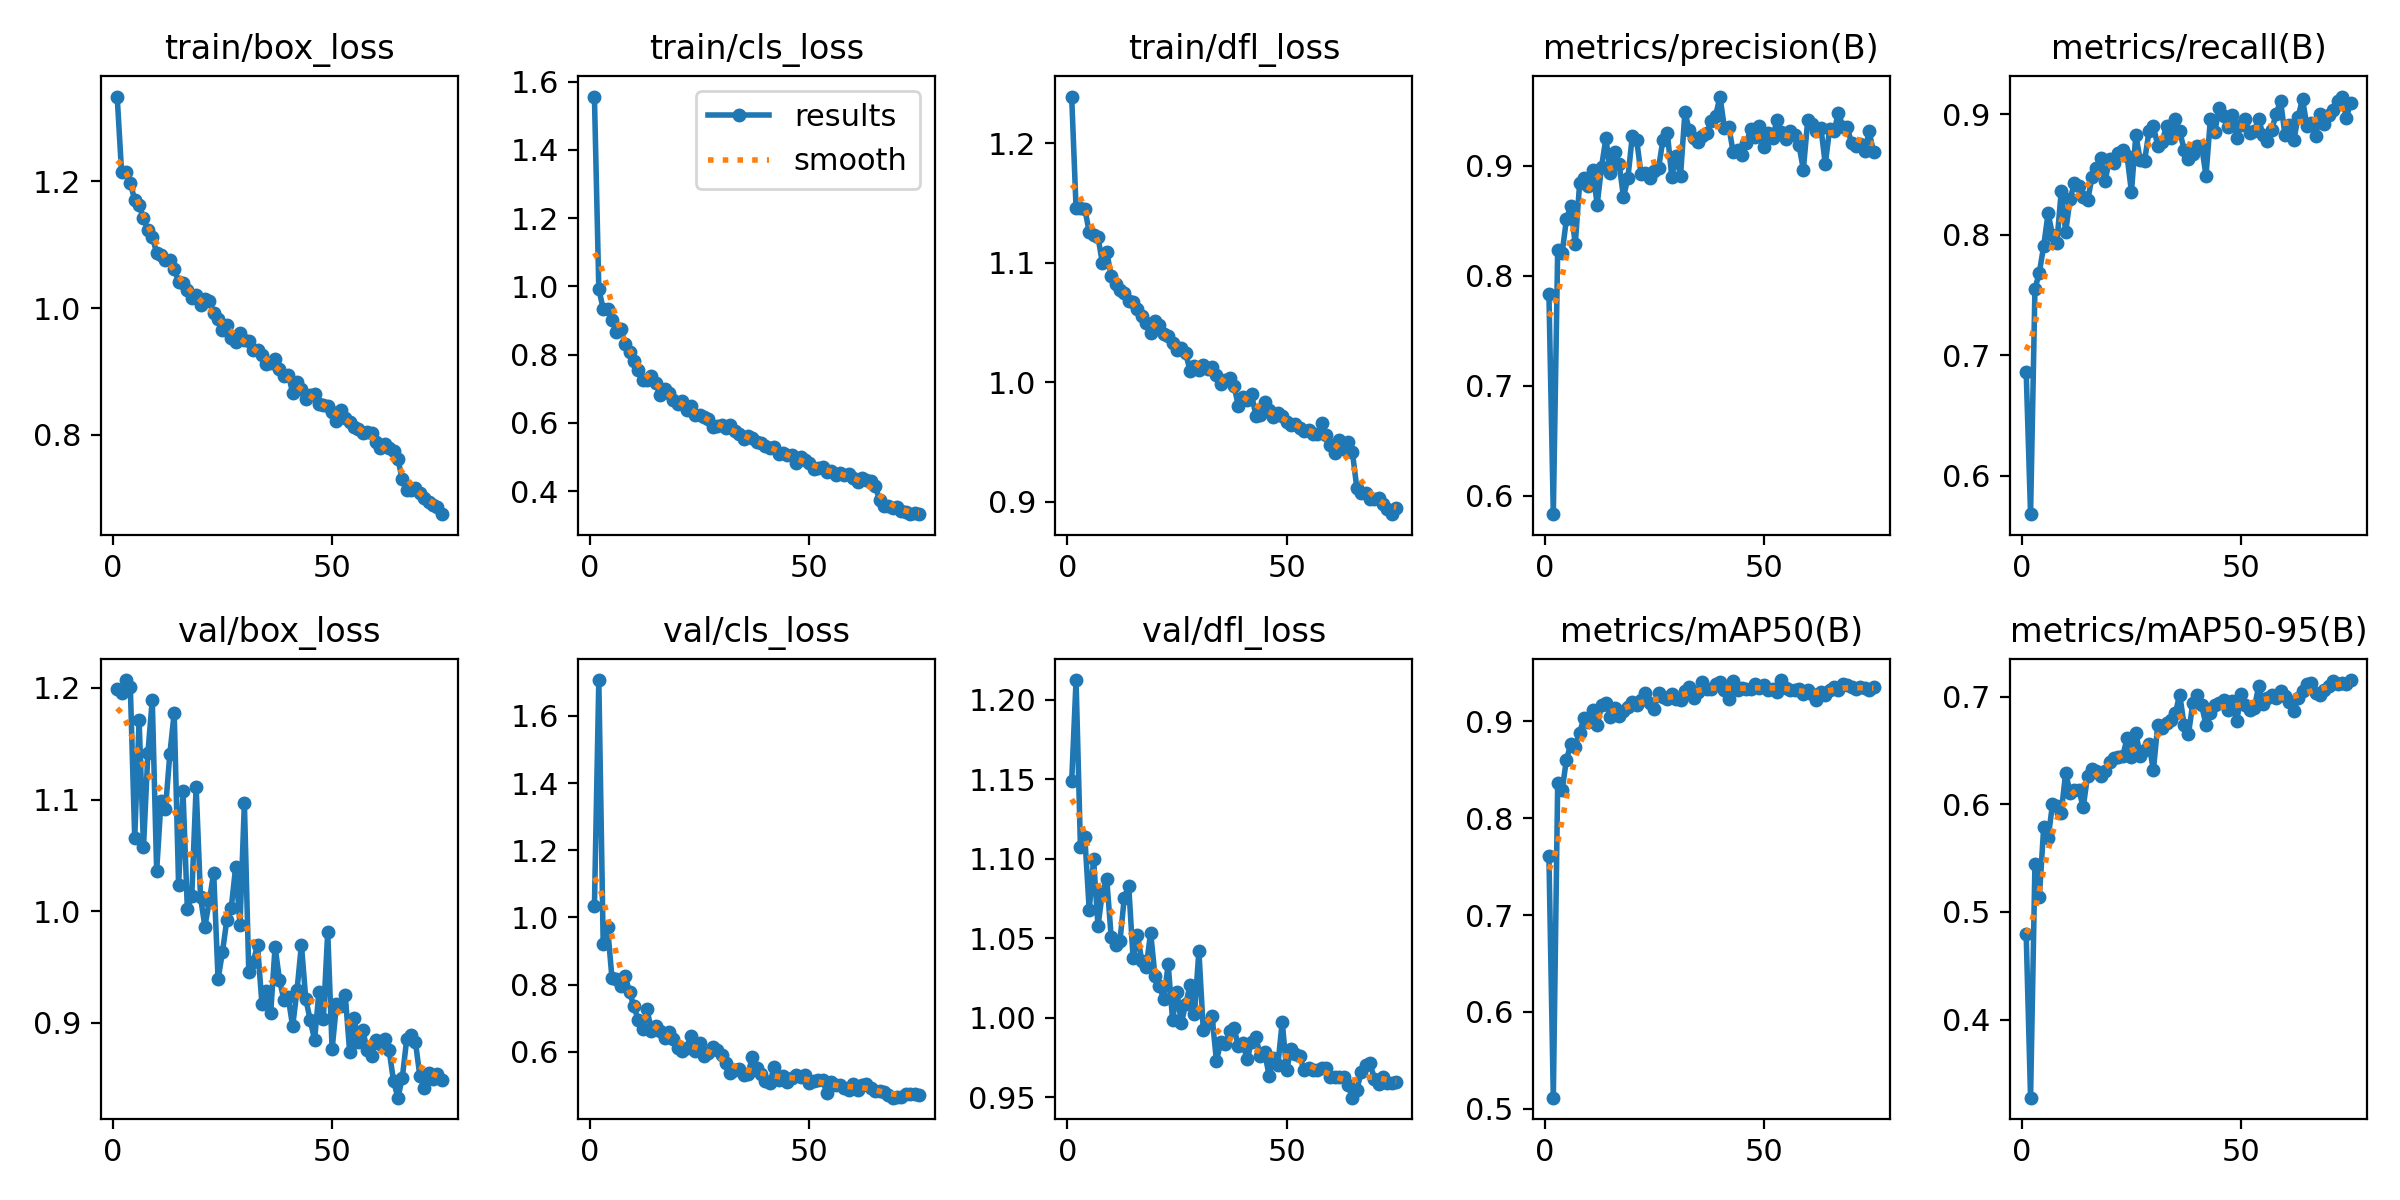


📊 confusion_matrix.png


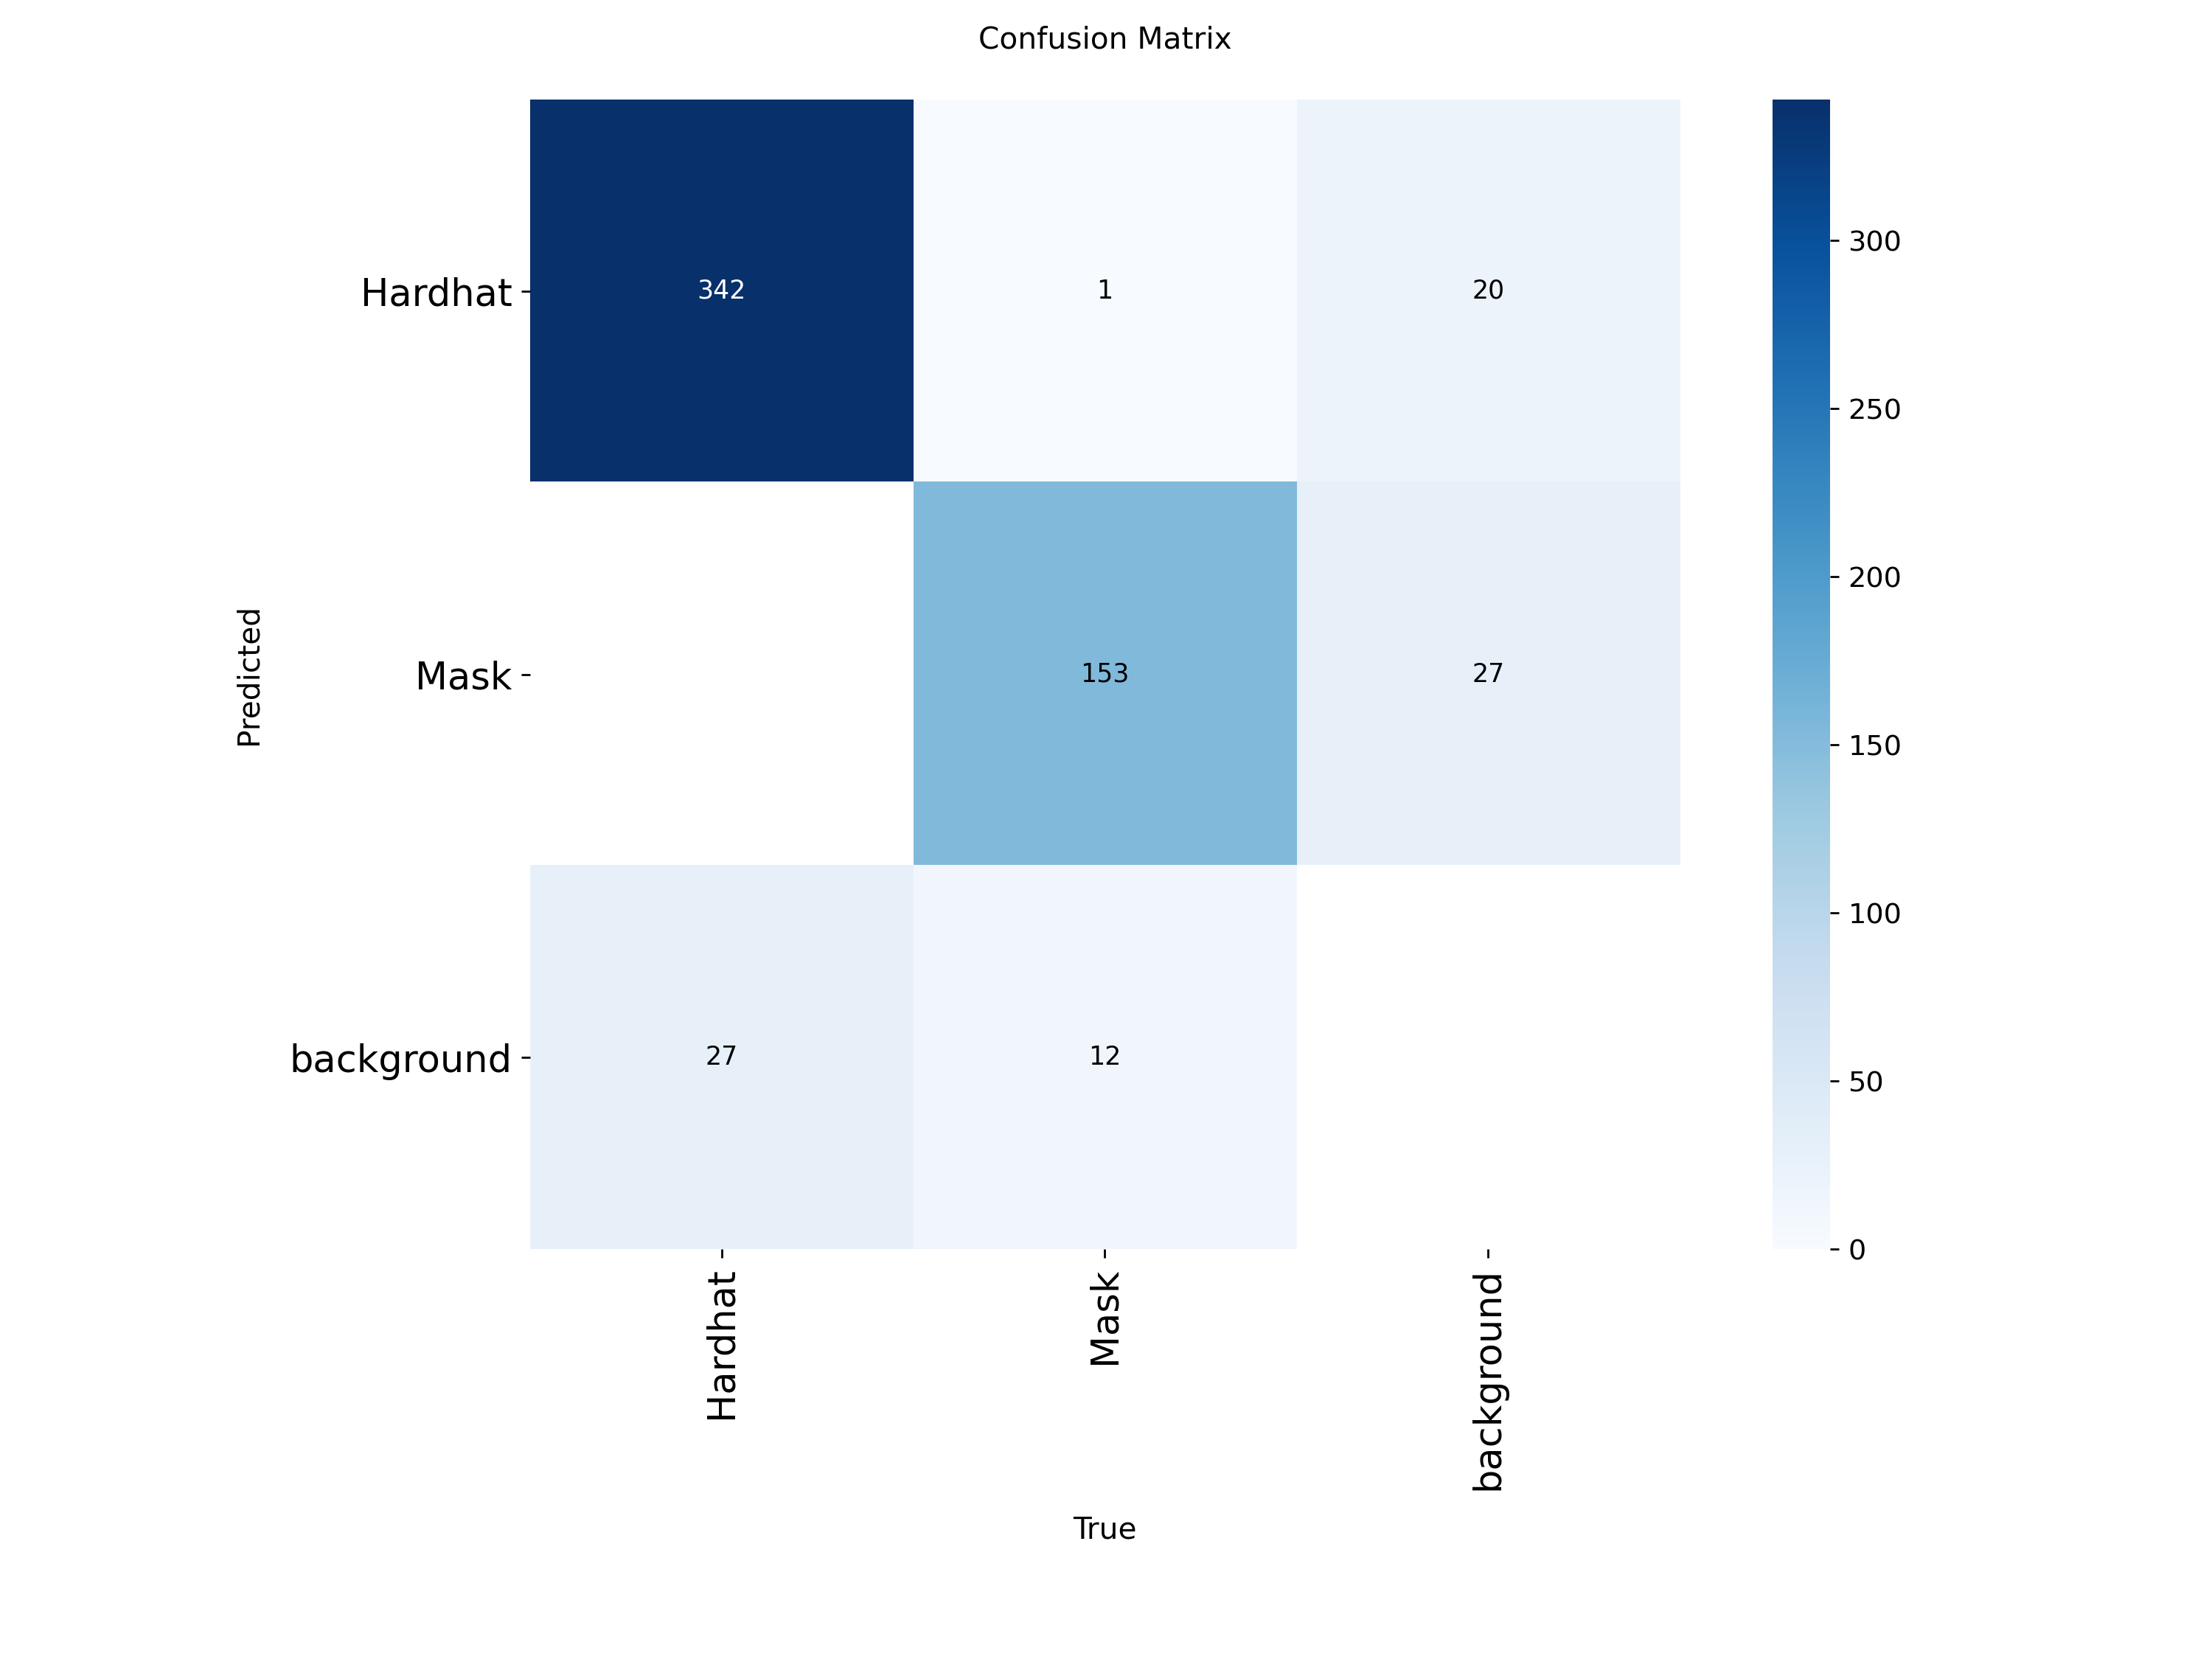


📊 PR_curve.png


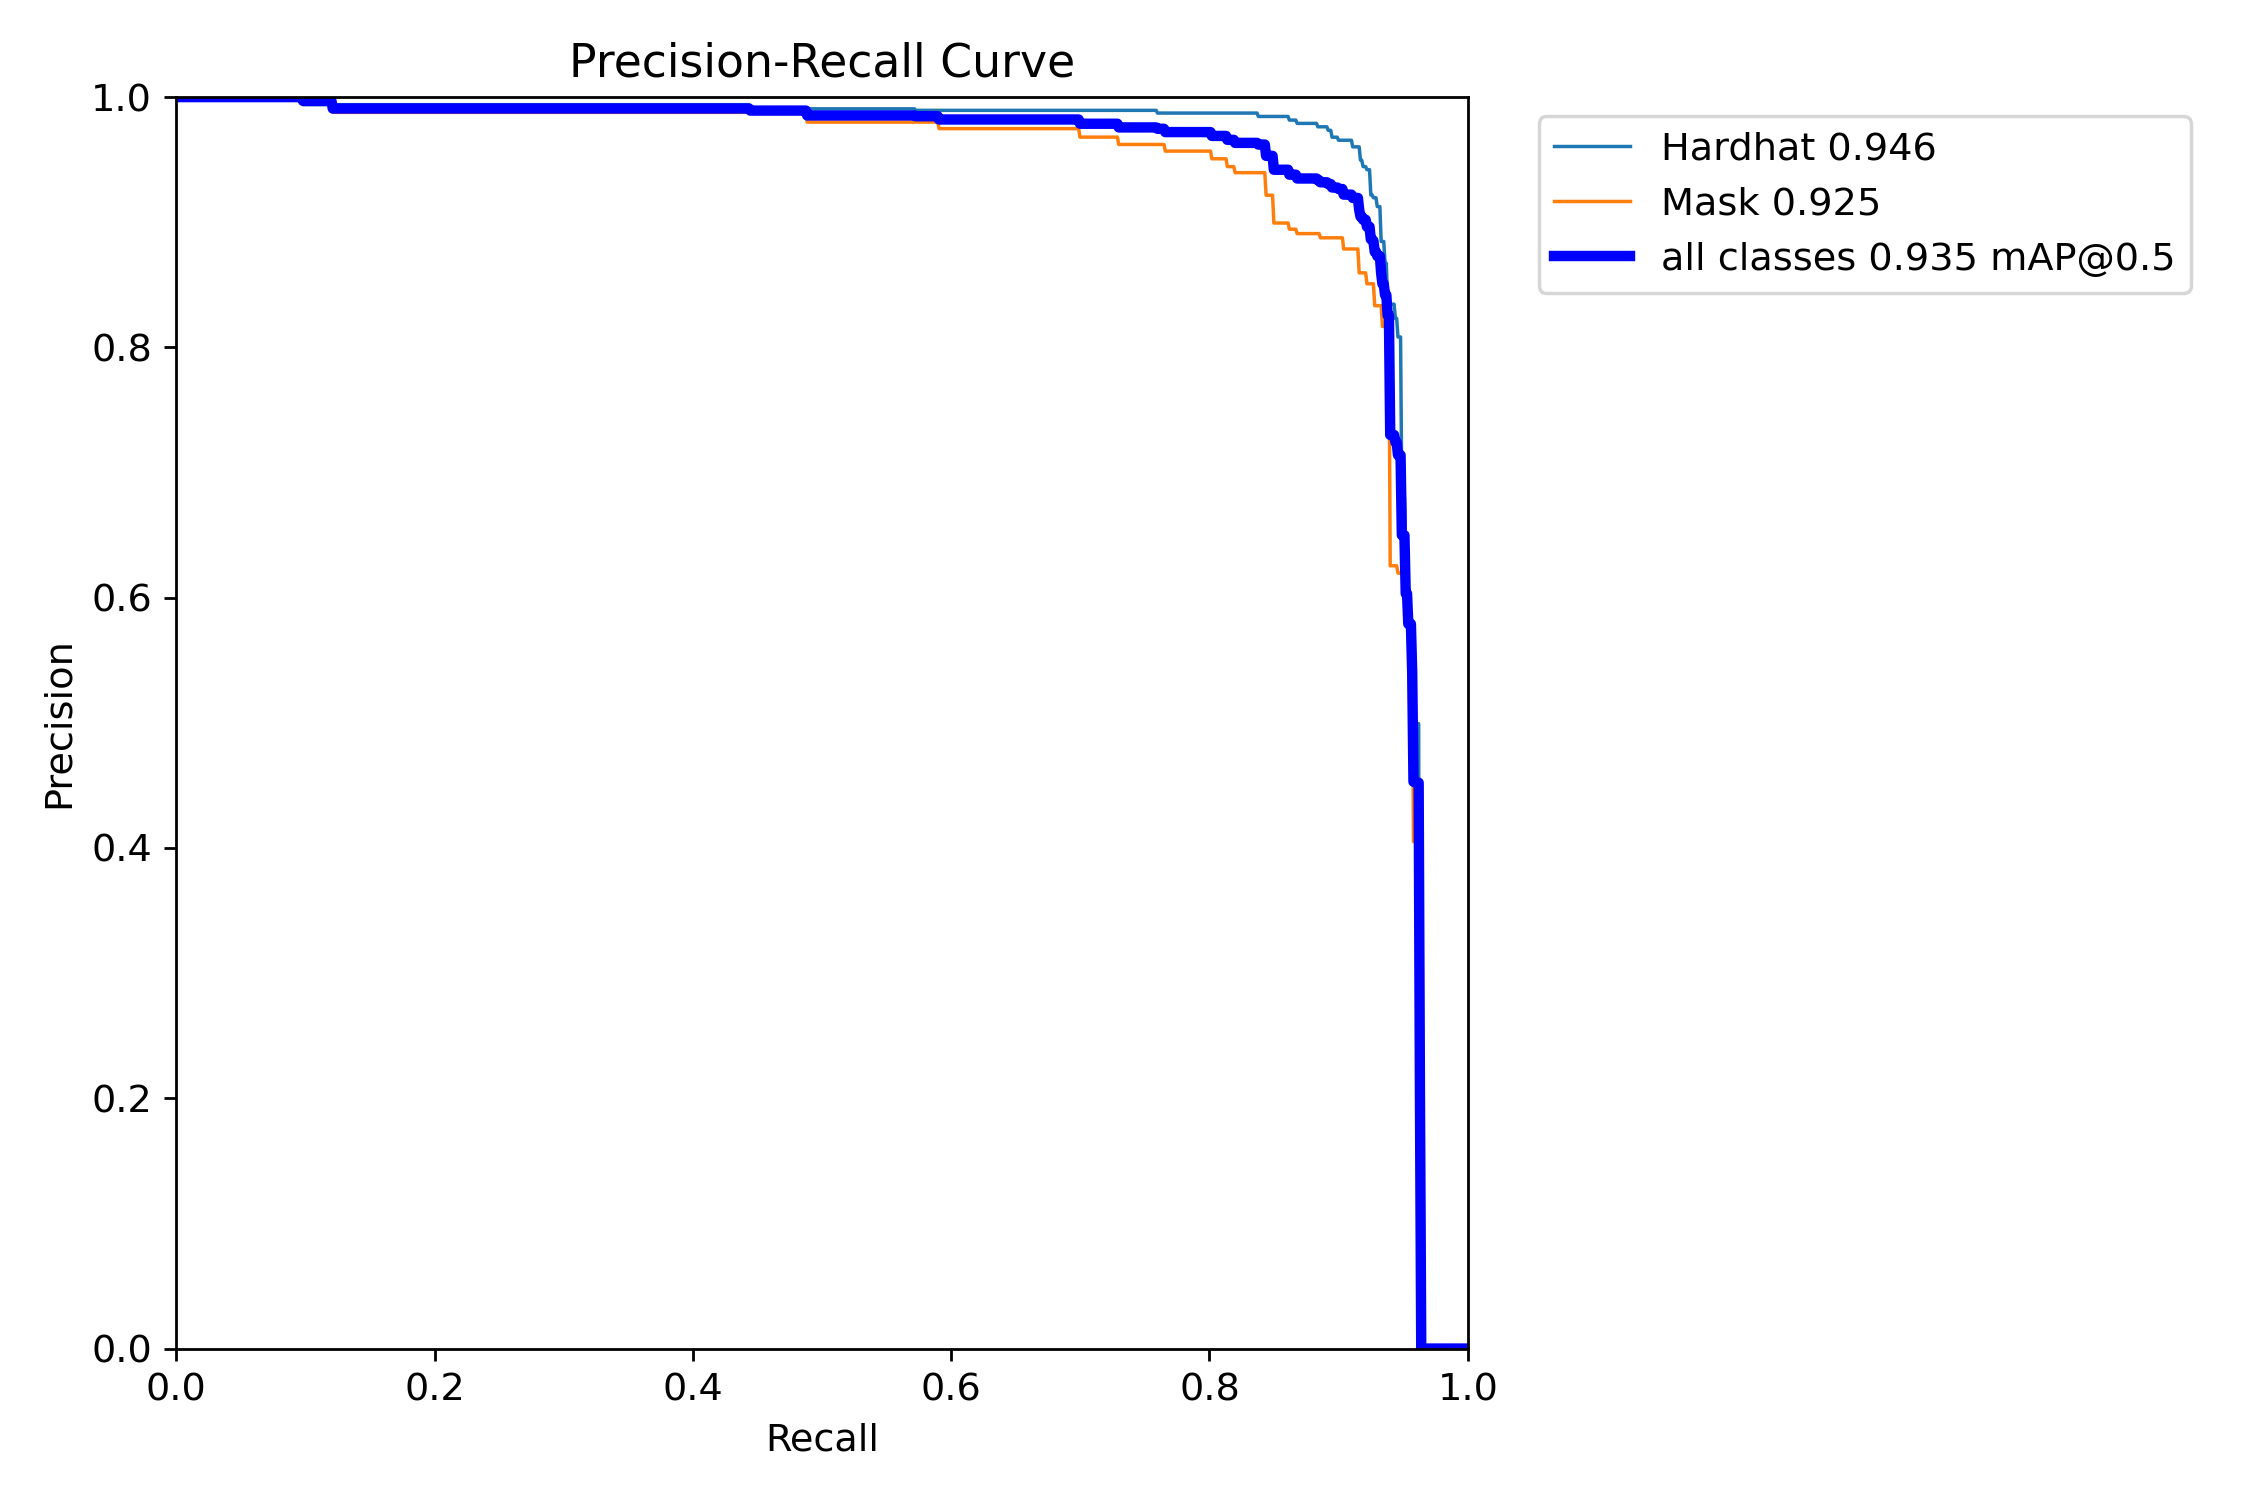


📊 F1_curve.png


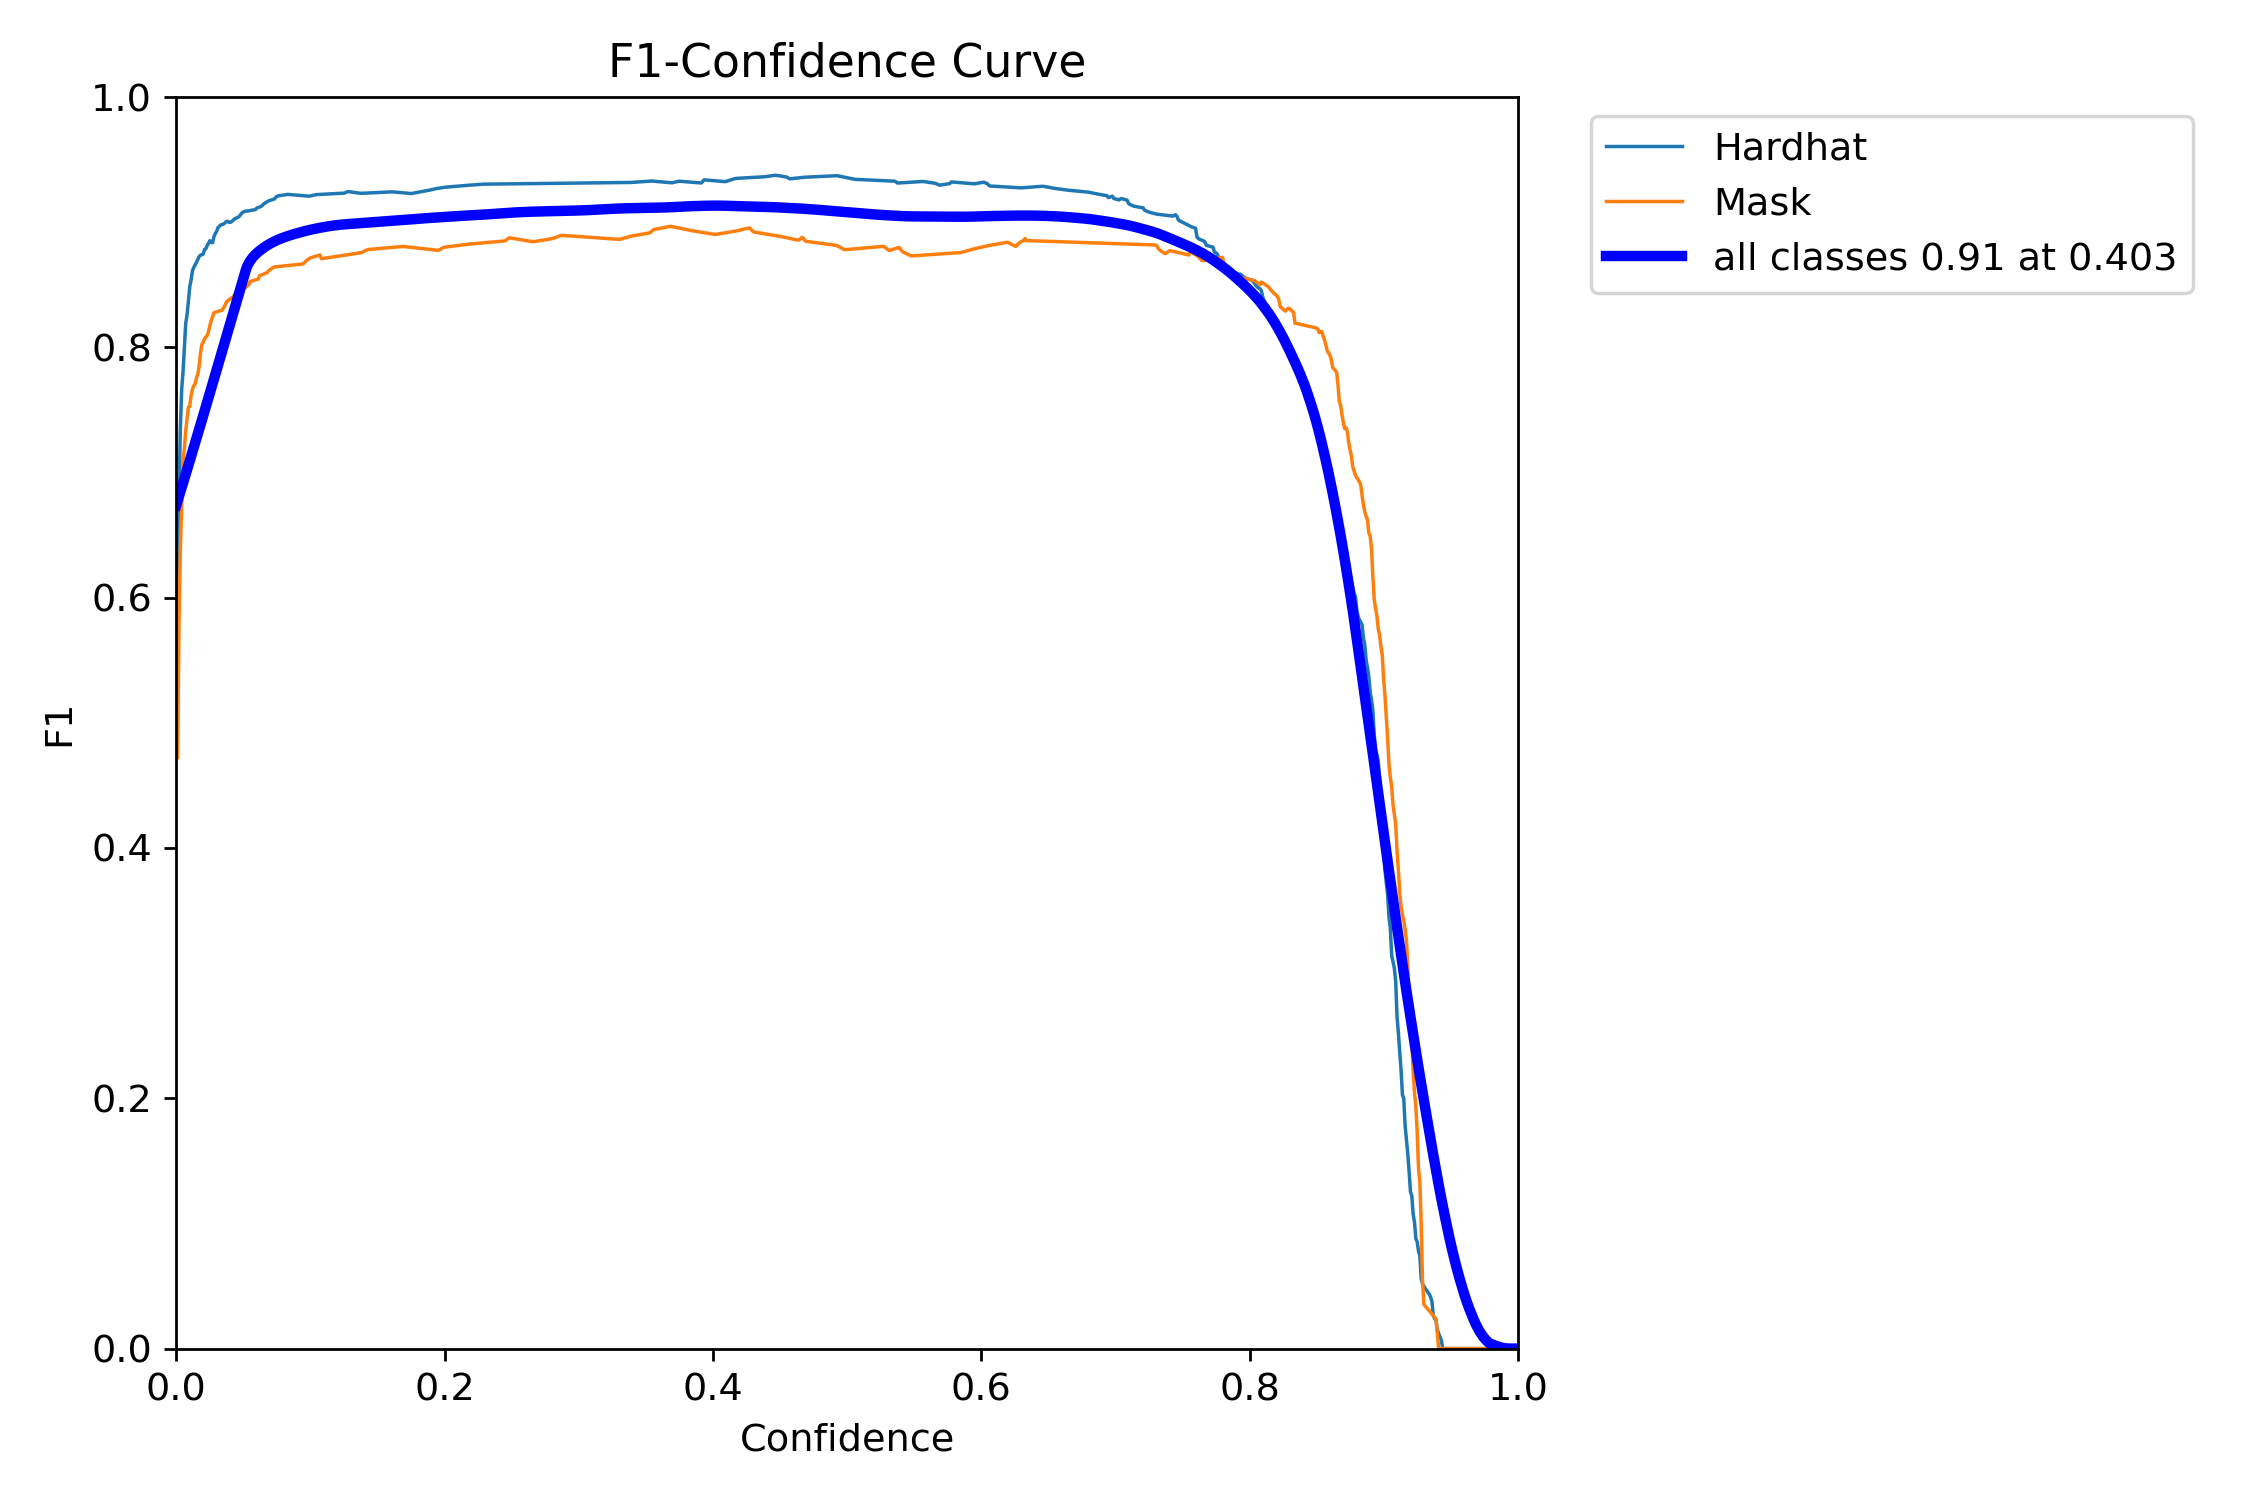


📊 BoxP_curve.png


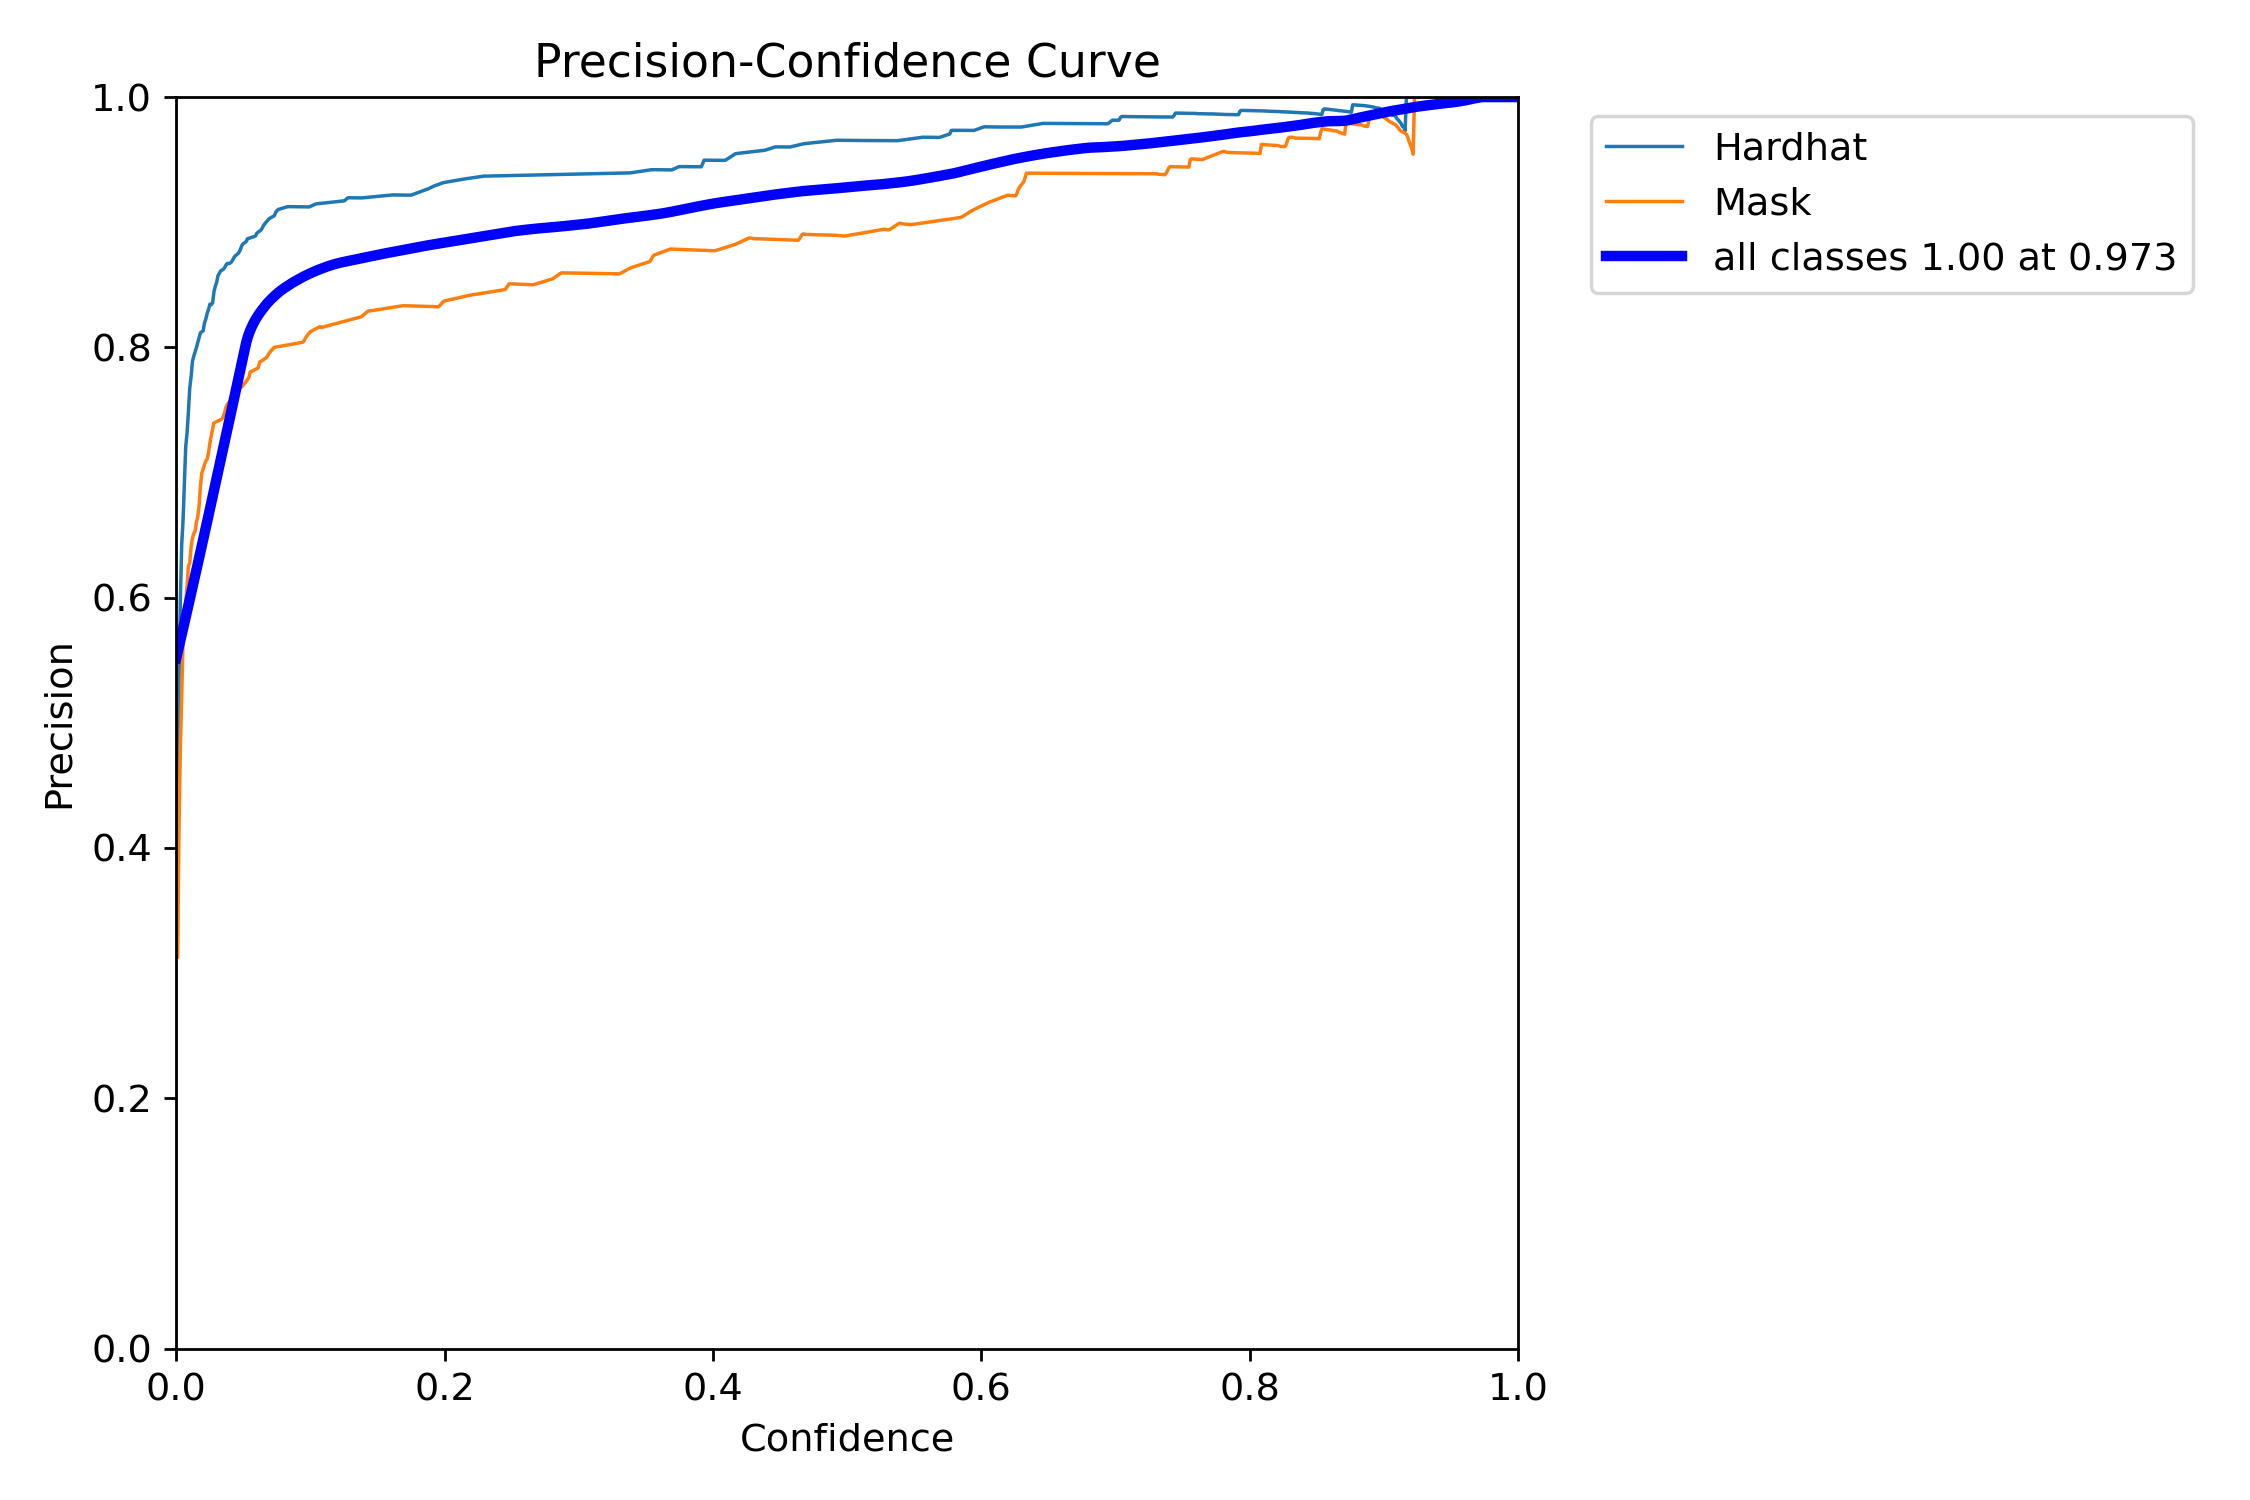


📊 confusion_matrix_normalized.png


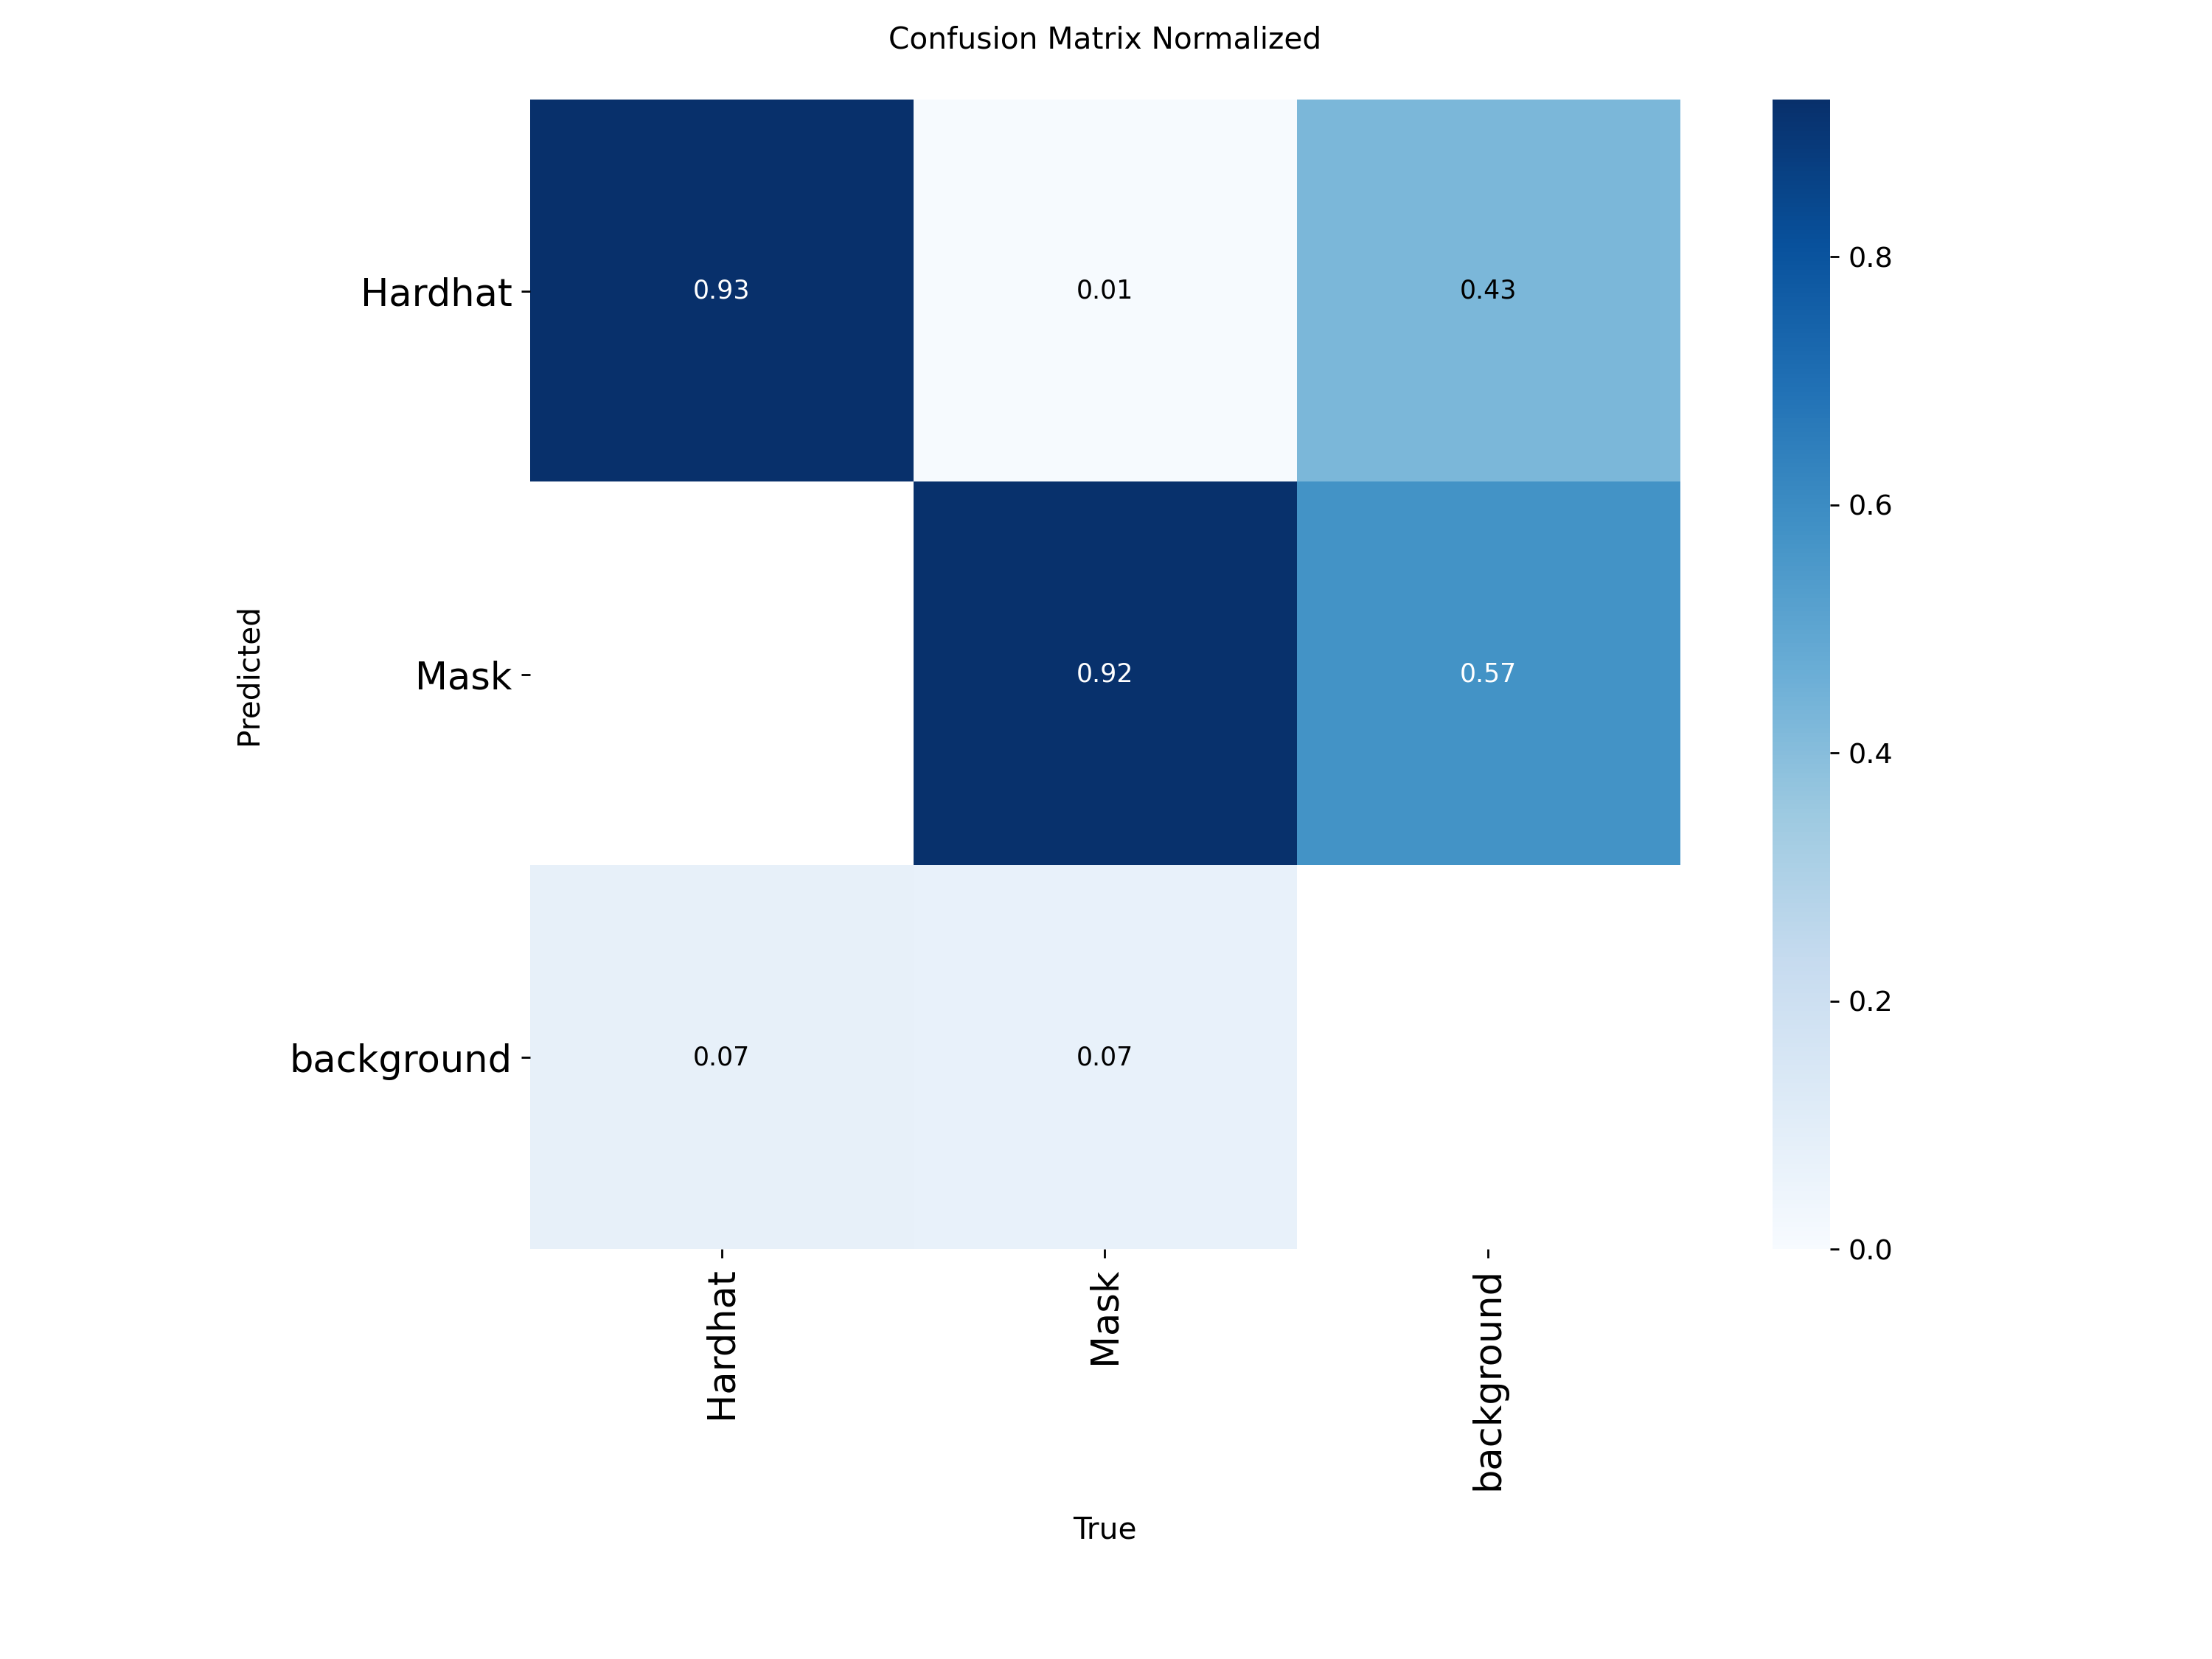


📊 BoxR_curve.png


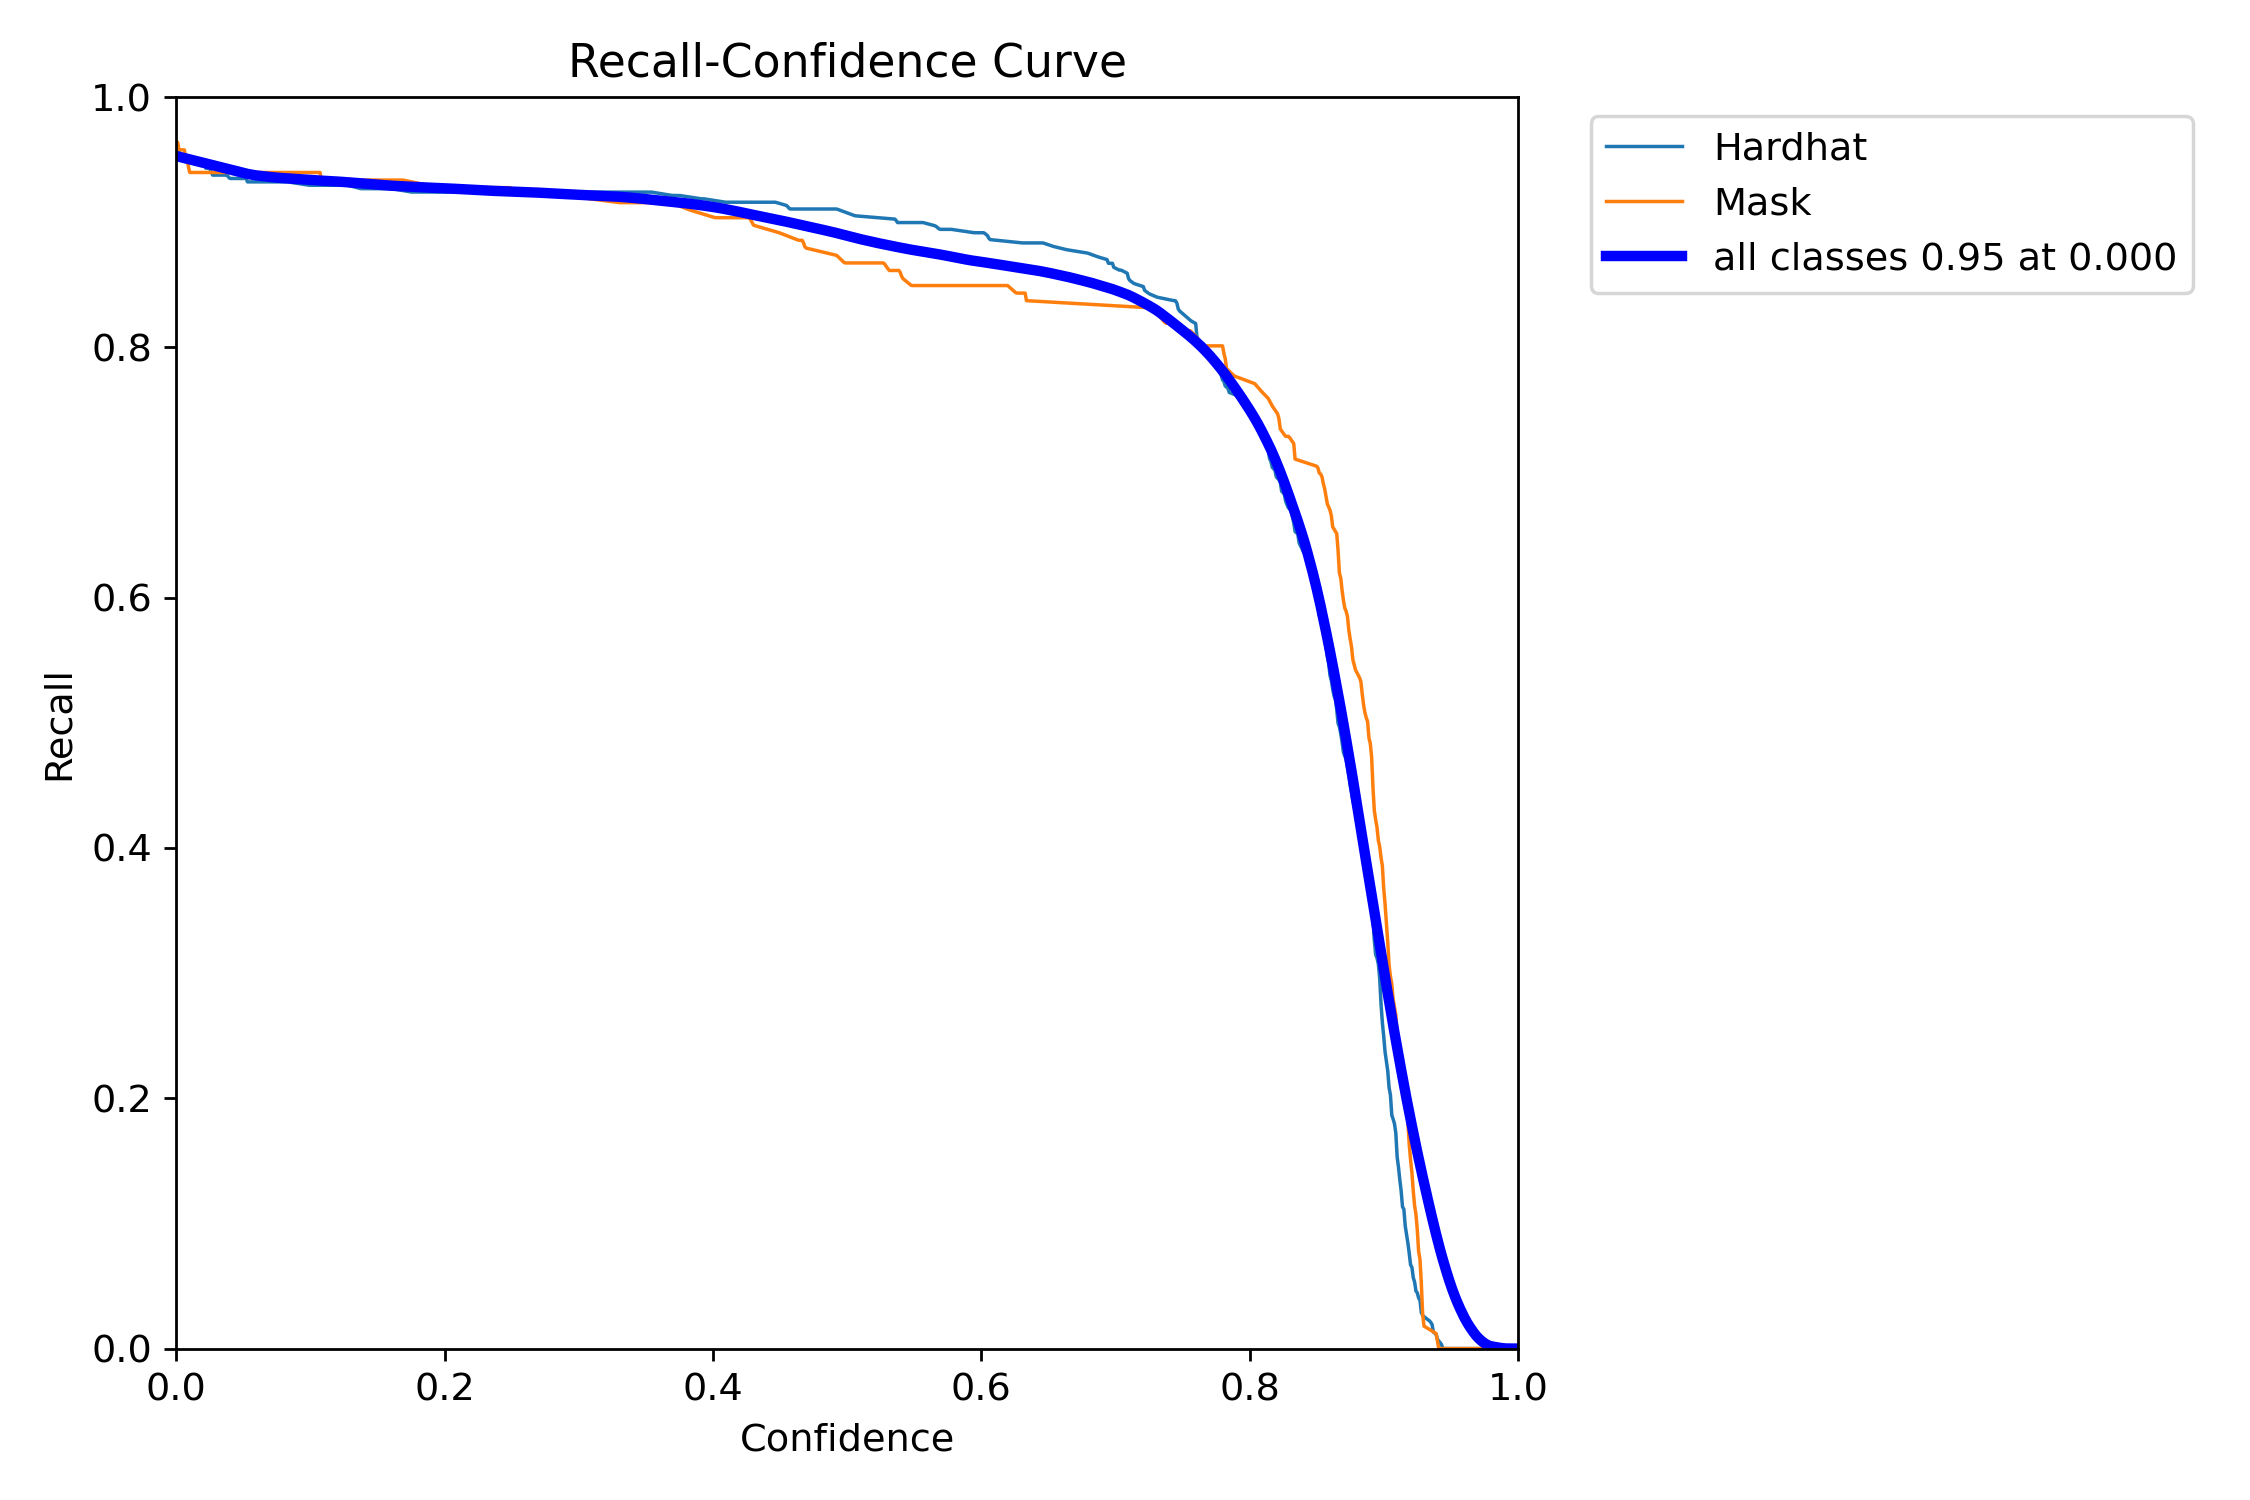

In [6]:
# =============================================
# Cell 5 — Lihat Grafik Hasil Training
# =============================================
from IPython.display import Image, display
import glob

TRAIN_DIR = f'/kaggle/working/runs/SafeK3/{EXPERIMENT}'

plot_files = glob.glob(f'{TRAIN_DIR}/*.png')
priority = ['results.png', 'confusion_matrix.png', 'PR_curve.png', 'F1_curve.png']

# Tampilkan priority plot dulu
shown = set()
for name in priority:
    for p in plot_files:
        if name in p and p not in shown:
            print(f'\n📊 {name}')
            display(Image(p))
            shown.add(p)

# Sisanya
for p in plot_files:
    if p not in shown:
        print(f'\n📊 {p.split("/")[-1]}')
        display(Image(p))

In [7]:
# =============================================
# Cell 6 — Validasi Model pada Test Set
# =============================================
from ultralytics import YOLO
from IPython.display import Image, display
import glob

BEST_MODEL_PATH = f'/kaggle/working/runs/SafeK3/{EXPERIMENT}/weights/best.pt'
FIXED_YAML      = '/kaggle/working/data_fixed.yaml'

best_model = YOLO(BEST_MODEL_PATH)
print(f'✅ Model loaded: {BEST_MODEL_PATH}')

print('\n🔍 Validasi pada test set...')
val_results = best_model.val(
    data   = FIXED_YAML,
    split  = 'test',
    imgsz  = 640,
    batch  = 16,
    device = 0,
    plots  = True,
)
print('\n✅ Validasi selesai!')

# Tampilkan confusion matrix
conf_matrix = glob.glob(f'/kaggle/working/runs/SafeK3/{EXPERIMENT}/val*/confusion_matrix*.png')
if conf_matrix:
    print('\n📊 Confusion Matrix:')
    display(Image(conf_matrix[0]))

✅ Model loaded: /kaggle/working/runs/SafeK3/SafeK3_Kaggle/weights/best.pt

🔍 Validasi pada test set...
Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1315.9±683.2 MB/s, size: 54.6 KB)
val: Scanning /kaggle/working/dataset/test/labels... 176 images, 36 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 176/176 1.4Kit/s 0.1s<0.1s
val: New cache created: /kaggle/working/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 3.6it/s 3.1s0.2s
                   all        176        488      0.871      0.903      0.921      0.714
               Hardhat        138        351      0.923      0.952      0.975      0.758
                  Mask         68        137      0.819      0.854      0.867      0.671
Speed: 2.0ms preprocess, 10.4ms inference, 0.0m

🖼️  Deteksi pada 6 gambar sample...


/tmp/ipykernel_58/627748050.py:76: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/627748050.py:78: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.savefig(SAMPLE_OUT, dpi=120, bbox_inches='tight')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


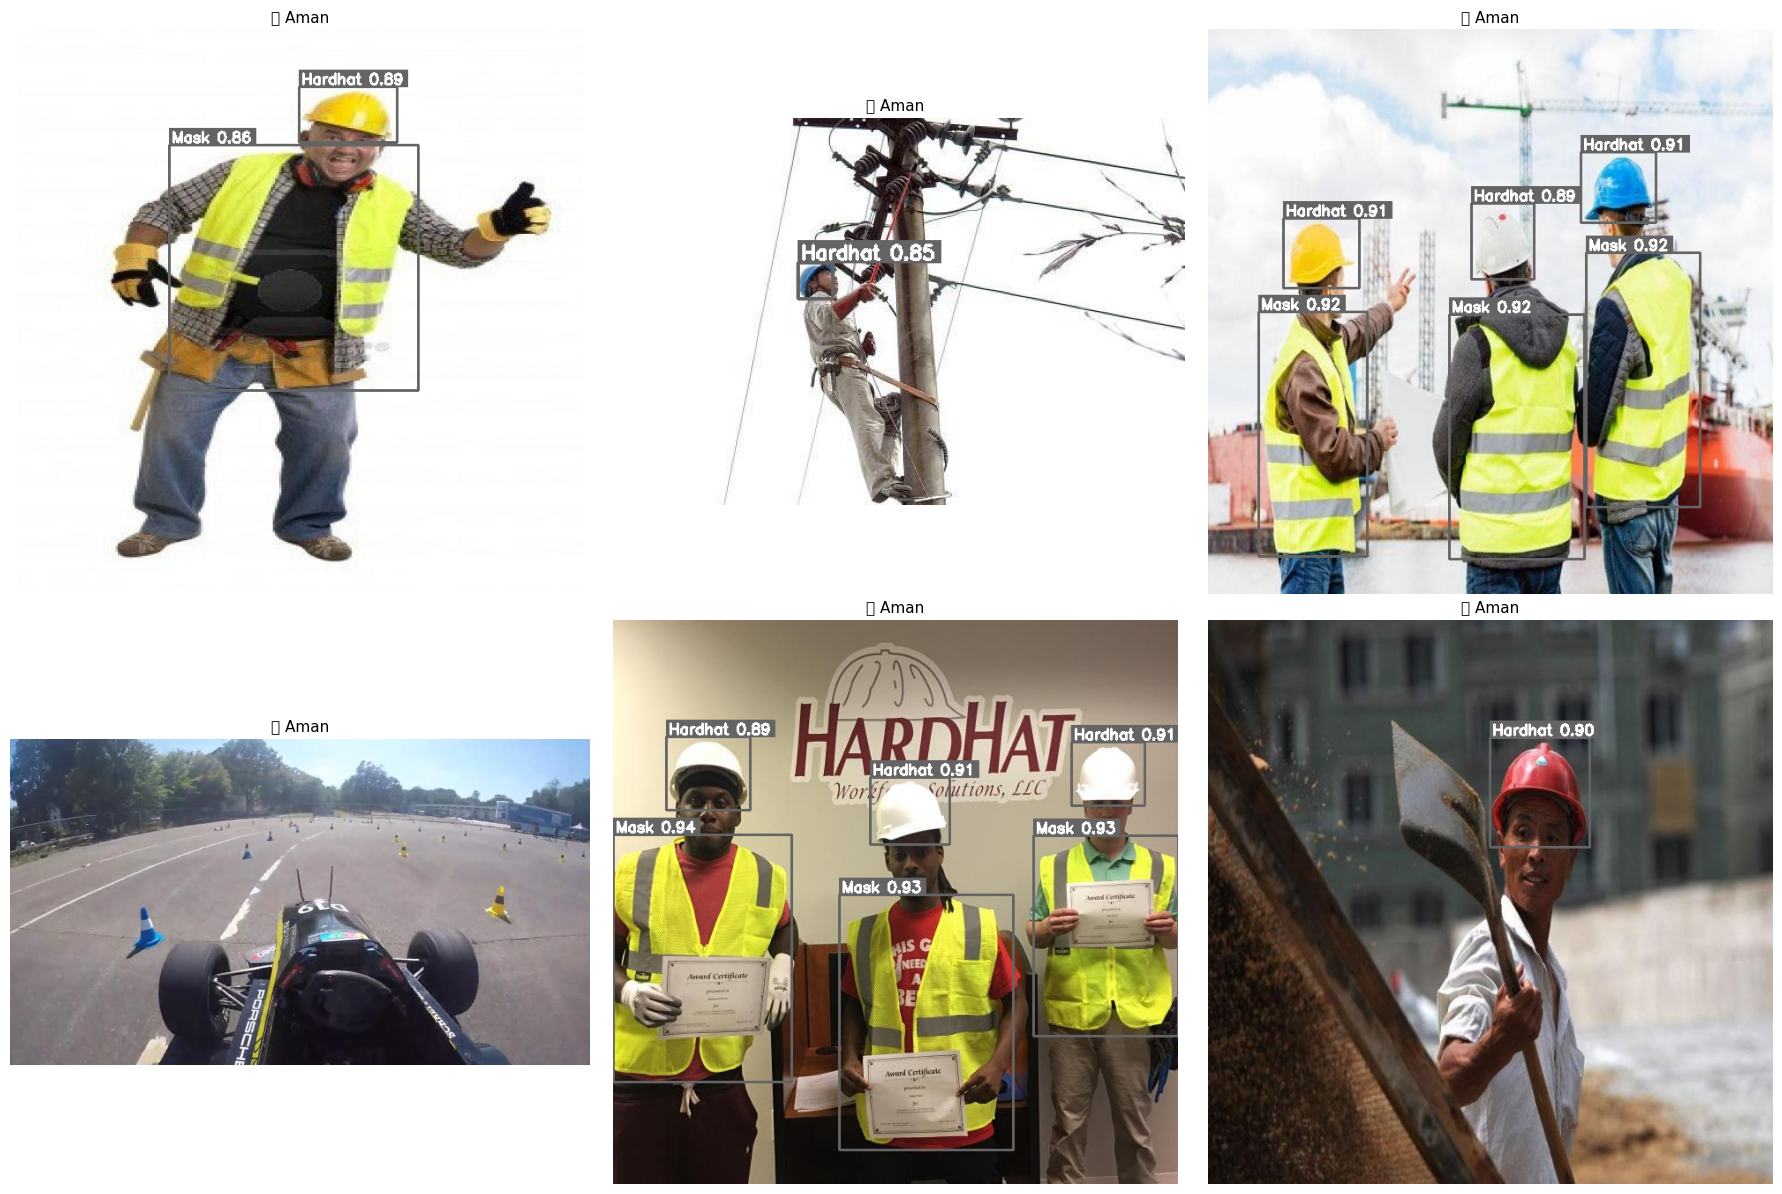


✅ Gambar tersimpan: /kaggle/working/sample_deteksi.png


In [8]:
# =============================================
# Cell 7 — Deteksi Sample Gambar dari Test Set
# =============================================
import cv2
import numpy as np
from pathlib import Path
import random
import matplotlib.pyplot as plt
import yaml

FIXED_YAML = '/kaggle/working/data_fixed.yaml'
with open(FIXED_YAML, 'r') as f:
    cfg = yaml.safe_load(f)

# Ambil gambar dari test set (fallback ke val)
test_dir = Path(cfg.get('test', cfg.get('val', '')))
test_imgs = list(test_dir.glob('*.jpg')) + list(test_dir.glob('*.png'))
sample_imgs = random.sample(test_imgs, min(6, len(test_imgs)))
print(f'🖼️  Deteksi pada {len(sample_imgs)} gambar sample...')

# Warna per kelas
CLASS_COLORS = {
    'helmet'     : (0, 255, 80),
    'no-helmet'  : (0, 60, 255),
    'no_helmet'  : (0, 60, 255),
    'vest'       : (255, 180, 0),
    'no-vest'    : (0, 80, 255),
    'no_vest'    : (0, 80, 255),
    'person'     : (180, 180, 180),
}

def get_color(label):
    label_lower = label.lower()
    for k, v in CLASS_COLORS.items():
        if k in label_lower:
            return v
    return (100, 100, 100)

cols = 3
rows = (len(sample_imgs) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 6))
axes = axes.flatten()

for i, img_path in enumerate(sample_imgs):
    frame   = cv2.imread(str(img_path))
    det     = best_model(frame, conf=0.4, verbose=False)[0]
    output  = frame.copy()
    violations = []

    for box in det.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        conf_s = float(box.conf[0])
        label  = best_model.names[int(box.cls[0])]
        color  = get_color(label)
        text   = f'{label} {conf_s:.2f}'

        if 'no-' in label.lower() or 'no_' in label.lower():
            violations.append(label)

        cv2.rectangle(output, (x1, y1), (x2, y2), color, 2)
        (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
        cv2.rectangle(output, (x1, y1 - th - 6), (x1 + tw + 6, y1), color, -1)
        cv2.putText(output, text, (x1 + 3, y1 - 3),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)

    status = f'⚠️ {", ".join(violations)}' if violations else '✅ Aman'
    rgb = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)
    axes[i].imshow(rgb)
    axes[i].set_title(status, fontsize=11)
    axes[i].axis('off')

# Sembunyikan axes kosong
for j in range(len(sample_imgs), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
SAMPLE_OUT = '/kaggle/working/sample_deteksi.png'
plt.savefig(SAMPLE_OUT, dpi=120, bbox_inches='tight')
plt.show()
print(f'\n✅ Gambar tersimpan: {SAMPLE_OUT}')

In [9]:
# =============================================
# Cell 8 — Export & Download Model
# =============================================
import shutil
from pathlib import Path

TRAIN_DIR = f'/kaggle/working/runs/SafeK3/{EXPERIMENT}'
BEST_PT   = f'{TRAIN_DIR}/weights/best.pt'
LAST_PT   = f'{TRAIN_DIR}/weights/last.pt'

# Zip seluruh folder training
ZIP_PATH = '/kaggle/working/SafeK3_hasil_training'
print('📦 Mengompres hasil training...')
shutil.make_archive(ZIP_PATH, 'zip', TRAIN_DIR)
zip_size = Path(ZIP_PATH + '.zip').stat().st_size / 1024 / 1024

print(f'\n✅ File siap didownload!')
print(f'   📁 {ZIP_PATH}.zip ({zip_size:.1f} MB)')
print(f'   Isi: best.pt, last.pt, results.png, confusion_matrix.png, dll')
print(f'\n📥 Cara download:')
print(f'   Panel kanan → Output → /kaggle/working → SafeK3_hasil_training.zip → Download')

# Info file model
for pt in [BEST_PT, LAST_PT]:
    if Path(pt).exists():
        size_mb = Path(pt).stat().st_size / 1024 / 1024
        print(f'\n   🤖 {Path(pt).name}: {size_mb:.1f} MB')

📦 Mengompres hasil training...

✅ File siap didownload!
   📁 /kaggle/working/SafeK3_hasil_training.zip (46.9 MB)
   Isi: best.pt, last.pt, results.png, confusion_matrix.png, dll

📥 Cara download:
   Panel kanan → Output → /kaggle/working → SafeK3_hasil_training.zip → Download

   🤖 best.pt: 21.5 MB

   🤖 last.pt: 21.5 MB
